# Notebook 9: Field-Weighted Citation Impact (FWCI)
Field-weighted citation impact (FWCI) is a [Snowball Metric](https://www.elsevier.com/insights/metrics/snowball-metrics) that quantifies citation performance relative to publications from the same field and publication year. It is a normalized metric that accounts for differences in citations across different years (and fields; but here all articles are from the same field), making it a more appropriate metric for comparing citation performance than raw citation counts.
<br><br>
Like in Notebook #7, we will compare FWCI between *sharing* and *non-sharing* articles, and then across the three sharing granularities (FIXATION, TRIAL, PARTICIPANT). The analysis is run at two steps: First, we use a uni-variate approach (t-test or Mann-Whitney U test, depending on normality). Second, we fit a multivariable regression to test whether the findings hold when controlling for other known predictors of article impact (e.g., number of authors, open-access status, etc.). Note that because FWCI is already normalized for publication year, we do not include *publication age* as a covariate in the regression model.
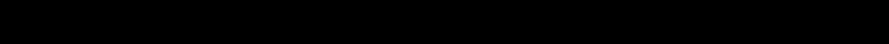
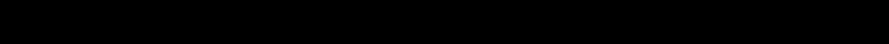
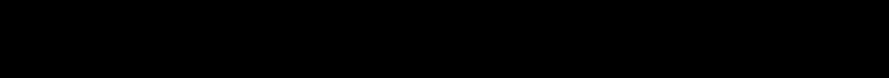

In [1]:
import numpy as np
import pandas as pd
import pingouin as pg
from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.outliers_influence import variance_inflation_factor
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import plotly.io as pio

from helpers.config import *
from helpers import dataset
from helpers.stats import compare_continuous
from helpers.plotting import save_figure

pio.renderers.default = "browser"

## Setup

In [2]:
combined, FEATURES_DF = dataset.load_or_build()
FWCI_DF = (
    pd.concat([
        FEATURES_DF, combined["FieldWeightedCitationIndex"], np.log(dataset.fwci_with_zeros_imputed(combined))
    ], axis=1)
    .rename(columns={"FieldWeightedCitationIndex": "FWCI", "fwci_with_zeros_imputed": "log(Imputed FWCI)"})
    .drop(columns=["log(Weeks Since Pub.)"])
)
FWCI_DF = dataset.to_smf_columns(FWCI_DF)

FWCI_DF.columns

Loaded cached dataset from C:\Users\nirjo\Documents\University\PhD\Projects\eye_movement_data_sharing\data_store (234 rows)


Index(['is_sharing_data', 'sharing_class', 'has_us_author', 'is_open_access',
       'has_preprint', 'log_number_of_authors', 'venue_impact', 'venue_name',
       'fwci', 'log_imputed_fwci'],
      dtype='str')

## Sharing vs. Non-Sharing

In [3]:
GROUPING_VARIABLE = "is_sharing_data"

### Univariate Comparison

In [4]:
# compare summary statistics of citation counts between sharing and non-sharing articles
FWCI_DF.groupby(GROUPING_VARIABLE)["fwci"].describe().T

is_sharing_data,0,1
count,154.000000,80.000000
mean,1.279551,1.653171
std,1.183644,1.443364
min,0.000000,0.000000
25%,0.451875,0.511600
50%,0.920250,1.195050
75%,1.562150,2.492800
max,6.559600,5.727700


In [5]:
# check for normality
sw_share = stats.shapiro(FWCI_DF[FWCI_DF[GROUPING_VARIABLE] == 1]["fwci"])
print(f"Sharing Group is Normal:\t\t{'YES' if sw_share.pvalue > 0.05 else 'NO'} (W={sw_share.statistic :.3f}; p={sw_share.pvalue :.3f})")

sw_non_share = stats.shapiro(FWCI_DF[FWCI_DF[GROUPING_VARIABLE] == 0]["fwci"])
print(f"Non-Sharing Group is Normal:\t{'YES' if sw_non_share.pvalue > 0.05 else 'NO'} (W={sw_non_share.statistic :.3f}; p={sw_non_share.pvalue :.3f})")

if sw_share.pvalue > 0.05 and sw_non_share.pvalue > 0.05:
    print("Both groups are normally distributed, using t-test.")
else:
    print("At least one group is not normally distributed, using Mann-Whitney U test.")

Sharing Group is Normal:		NO (W=0.880; p=0.000)
Non-Sharing Group is Normal:	NO (W=0.833; p=0.000)
At least one group is not normally distributed, using Mann-Whitney U test.


In [6]:
# run univariate test
fwci_univariate_test_results, citations_univariate_summary = compare_continuous(
    data=FWCI_DF,
    share_feature=GROUPING_VARIABLE,
    tested_feature="fwci",
    alternative="greater",
    verbose=False
)
fwci_univariate_test_results = pd.Series(fwci_univariate_test_results).rename("fwci")
is_significant = fwci_univariate_test_results.loc["p_val"] < 0.05

print(f"Univariate test is {'' if is_significant else 'NOT '}significant ({fwci_univariate_test_results.loc['test']}={fwci_univariate_test_results.loc['statistic']:.3f}, p={fwci_univariate_test_results.loc['p_val']:.4f})")

fwci_univariate_test_results

Univariate test is significant (MW_U=6999.000, p=0.0439)


test                                                         MW_U
alternative                                               greater
statistic                                                  6999.0
p_val                                                    0.043902
effect_sizes    {'rank-biserial': 0.1362012987012987, 'CLES': ...
Name: fwci, dtype: object

### Multivariable Regression
We compare *sharing* vs. *non-sharing* articles while controlling for other known predictors of citation impact. We use three differnt models, varying in the way they account for the venue of publication:
- The first model is a simple OLS regression, using the venue impact score as a covariate.
- The second model is a mixed-effects model, with venue as a random effect.
- The third model merges the two approaches, using a LME with venue impact as a fixed effect and venue as a random effect. This is the most conservative model, and the one we report in the manuscript.

#### Model 1 :: OLS
Model 1 uses venue impact scores as a covariate, and does not account for the venue of publication as a random effect. The model is specified as follows:
$$ log(\text{Imputed FWCI}) \sim 1 + C(\text{Sharing Status}) + C(\text{Is OA}) + C(\text{Has US Author}) + C(\text{Has Preprint}) + log(\text{Number of Authors}) + \text{Impact Score} $$

In [8]:
model1 = smf.ols(
    f"log_imputed_fwci ~ C({GROUPING_VARIABLE}) + C(has_us_author) + C(is_open_access) + C(has_preprint) + log_number_of_authors + venue_impact",
    data=FWCI_DF,
    drop_cols=["sharing_class"]
).fit()

model1.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:       log_imputed_fwci   R-squared:                       0.085
Model:                            OLS   Adj. R-squared:                  0.061
Method:                 Least Squares   F-statistic:                     3.530
Date:                Sun, 11 Oct 2026   Prob (F-statistic):            0.00232
Time:                        15:48:24   Log-Likelihood:                -331.12
No. Observations:                 234   AIC:                             676.2
Df Residuals:                     227   BIC:                             700.4
Df Model:                           6                                         
Covariance Type:            nonrobust                                         
===========================================================================================
                              coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------------
Intercept                  -1.0752      0.271     -3.972      0.000      -1.609      -0.542
C(is_sharing_data)[T.1]     0.0925      0.150      0.615      0.539      -0.204       0.389
C(has_us_author)[T.1]       0.2938      0.134      2.186      0.030       0.029       0.559
C(is_open_access)[T.1]      0.3858      0.189      2.043      0.042       0.014       0.758
C(has_preprint)[T.1]        0.1975      0.173      1.140      0.256      -0.144       0.539
log_number_of_authors       0.0918      0.158      0.580      0.563      -0.220       0.404
venue_impact                0.1437      0.054      2.650      0.009       0.037       0.251
==============================================================================
Omnibus:                        7.298   Durbin-Watson:                   2.056
Prob(Omnibus):                  0.026   Jarque-Bera (JB):                7.580
Skew:                          -0.433   Prob(JB):                       0.0226
Kurtosis:                       2.833   Cond. No.                         14.7
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

#### Model 2 :: Mixed-Effects
Model 2 uses venue as a random effect, and does not include the venue impact score as a covariate. The model is specified as follows:
$$ log(\text{Imputed FWCI}) \sim 1 + C(\text{Sharing Status}) + C(\text{Is OA}) + C(\text{Has US Author}) + C(\text{Has Preprint}) + log(\text{Number of Authors}) + (1 | \text{Venue}) $$

In [9]:
model2 = smf.mixedlm(
    f"log_imputed_fwci ~ C({GROUPING_VARIABLE}) + C(has_us_author) + C(is_open_access) + C(has_preprint) + log_number_of_authors",
    data=FWCI_DF,
    groups=FWCI_DF["venue_name"],
    drop_cols=["sharing_class"]
).fit(reml=False)

model2.summary()

C:\Users\nirjo\Documents\University\PhD\Projects\eye_movement_data_sharing\.venv\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
C:\Users\nirjo\Documents\University\PhD\Projects\eye_movement_data_sharing\.venv\Lib\site-packages\statsmodels\regression\mixed_linear_model.py:2200: ConvergenceWarning: Retrying MixedLM optimization with lbfgs
  warnings.warn(


<class 'statsmodels.iolib.summary2.Summary'>
"""
              Mixed Linear Model Regression Results
==================================================================
Model:              MixedLM  Dependent Variable:  log_imputed_fwci
No. Observations:   234      Method:              ML              
No. Groups:         23       Scale:               0.9511          
Min. group size:    1        Log-Likelihood:      -331.4833       
Max. group size:    43       Converged:           Yes             
Mean group size:    10.2                                          
------------------------------------------------------------------
                        Coef.  Std.Err.   z    P>|z| [0.025 0.975]
------------------------------------------------------------------
Intercept               -0.757    0.274 -2.762 0.006 -1.294 -0.220
C(is_sharing_data)[T.1]  0.126    0.153  0.824 0.410 -0.174  0.426
C(has_us_author)[T.1]    0.269    0.133  2.030 0.042  0.009  0.529
C(is_open_access)[T.1]   0.381    0.207  1.837 0.066 -0.026  0.787
C(has_preprint)[T.1]     0.120    0.173  0.697 0.486 -0.218  0.459
log_number_of_authors    0.148    0.156  0.946 0.344 -0.159  0.454
Group Var                0.067    0.052                           
==================================================================

"""

#### Model 3 :: Mixed-Effects with Venue Impact
Model 3 uses venue as a random effect, and includes the venue impact score as a covariate. The model is specified as follows:
$$ log(\text{Imputed FWCI}) \sim 1 + C(\text{Sharing Status}) + C(\text{Is OA}) + C(\text{Has US Author}) + C(\text{Has Preprint}) + log(\text{Number of Authors}) + \text{Impact Score} + (1 | \text{Venue}) $$

In [10]:
model3 = smf.mixedlm(
    f"log_imputed_fwci ~ C({GROUPING_VARIABLE}) + C(has_us_author) + C(is_open_access) + C(has_preprint) + log_number_of_authors + venue_impact",
    data=FWCI_DF,
    groups=FWCI_DF["venue_name"],
    drop_cols=["sharing_class"]
).fit(reml=False)

model3.summary()

<class 'statsmodels.iolib.summary2.Summary'>
"""
              Mixed Linear Model Regression Results
==================================================================
Model:              MixedLM  Dependent Variable:  log_imputed_fwci
No. Observations:   234      Method:              ML              
No. Groups:         23       Scale:               0.9280          
Min. group size:    1        Log-Likelihood:      -328.1216       
Max. group size:    43       Converged:           Yes             
Mean group size:    10.2                                          
------------------------------------------------------------------
                        Coef.  Std.Err.   z    P>|z| [0.025 0.975]
------------------------------------------------------------------
Intercept               -1.139    0.307 -3.711 0.000 -1.741 -0.538
C(is_sharing_data)[T.1]  0.072    0.151  0.475 0.635 -0.224  0.368
C(has_us_author)[T.1]    0.250    0.131  1.909 0.056 -0.007  0.506
C(is_open_access)[T.1]   0.376    0.203  1.849 0.065 -0.023  0.774
C(has_preprint)[T.1]     0.114    0.170  0.670 0.503 -0.219  0.446
log_number_of_authors    0.102    0.155  0.659 0.510 -0.202  0.406
venue_impact             0.186    0.074  2.530 0.011  0.042  0.331
Group Var                0.057    0.045                           
==================================================================

"""

In [ ]:
1/0

### (1) FWCI
#### (1A) Sharing / Non-Sharing Articles

In [ ]:
not_sharing_fwci = combined.loc[~combined["is_sharing_data"], "FieldWeightedCitationIndex"]
sharing_fwci = combined.loc[combined["is_sharing_data"], "FieldWeightedCitationIndex"]

# check normality of FWCI distributions:
print("Is FWCI normally distributed for non-sharing articles?")
fwci_non_sharing_shapiro = stats.shapiro(not_sharing_fwci)
print(f"{"YES" if fwci_non_sharing_shapiro.pvalue > 0.05 else "NO"} (W={fwci_non_sharing_shapiro.statistic:.3f}, p={fwci_non_sharing_shapiro.pvalue:.4f})\n")

print("Is FWCI normally distributed for sharing articles?")
fwci_sharing_shapiro = stats.shapiro(sharing_fwci)
print(f"{"YES" if fwci_sharing_shapiro.pvalue > 0.05 else "NO"} (W={fwci_sharing_shapiro.statistic:.3f}, p={fwci_sharing_shapiro.pvalue:.4f})")

In [ ]:
fwci_pair_test = stats.mannwhitneyu(not_sharing_fwci, sharing_fwci, alternative="less")

# calculate effect size (rank-biserial correlation / CLES)
n1, n2 = len(not_sharing_fwci), len(sharing_fwci)
U_nonshare = fwci_pair_test.statistic
U_share = n1 * n2 - U_nonshare
rank_biserial_corr = (U_share - U_nonshare) / (n1 * n2)
cles = U_share / (n1 * n2)

print("Share / Non-Share FWCI Comparison:")
print("Mann-Whitney U Test:" + f"\tU={fwci_pair_test.statistic},\tp={fwci_pair_test.pvalue:.4f}")
print("{0: <20}".format("Effect Sizes:") + f"\tRBC: {rank_biserial_corr:.3f}\tCLES: {cles:.3f}")

# re-run statistical test with `pingouin` for robustness:
pg.mwu(not_sharing_fwci, sharing_fwci, alternative="less")

#### (1B) Data Sharing Class

In [ ]:
# check normality of FWCI distributions for each sharing class:
share_group_fwci = []
for share_group in ["FIXATION", "TRIAL", "PARTICIPANT"]:
    group_fwci = (
        combined
        .loc[combined["data_sharing_class"] == share_group, "FieldWeightedCitationIndex"]
        .dropna()
        .reset_index(drop=True)
        .rename(share_group)
    )
    share_group_fwci.append(group_fwci)
    shapiro_result = stats.shapiro(group_fwci)
    print(f"Is FWCI normally distributed for {share_group} sharing articles?")
    print(f"{"YES" if shapiro_result.pvalue > 0.05 else "NO"} (W={shapiro_result.statistic:.3f}, p={shapiro_result.pvalue:.4f})\n")

# run Kruskal-Wallis H-test:
fwci_sharegroup_test = stats.kruskal(*share_group_fwci)
fwci_sharegroup_test

#### Visualizing Share/Non-Share FWCI Comparison

In [ ]:
suplot_titles = ["Sharing vs. Non-Sharing", "Different Types of Data Sharing"]
fwci_fig = make_subplots(
    rows=1, cols=len(suplot_titles), column_titles=suplot_titles,
    shared_yaxes=True, horizontal_spacing=0.025, vertical_spacing=0.025,
)

# (1) Sharing vs. Non-Sharing
left_subplot_data_long = (
    combined
    .melt(
        id_vars=['is_sharing_data'],
        value_vars=['FieldWeightedCitationIndex'],
        var_name='name',
        value_name='value'
    )
    .replace({
        'FieldWeightedCitationIndex': 'FWCI',
    })
)
max_y = left_subplot_data_long["value"].max()
for is_share in left_subplot_data_long["is_sharing_data"].unique():
    subset = left_subplot_data_long[left_subplot_data_long["is_sharing_data"] == is_share]
    subset_name = 'Sharing' if is_share else 'Not Sharing'
    color = CLASS_COLORS[subset_name.upper()]
    fwci_fig.add_trace(
        row=1, col=1,
        trace=go.Violin(
            x=subset['name'], y=subset['value'],
            name=subset_name, legendgroup=subset_name, scalegroup=subset_name,
            side='positive' if is_share else 'negative',
            fillcolor=color, line_color=color,
            width=0.9, spanmode="hard",
            points=False, pointpos=0, jitter=0.5,
            box=dict(visible=False, width=0.5, line=dict(color="black")),
            meanline=dict(visible=False, color='black'),
        )
    )
    # annotate half-violin
    fwci_fig.add_annotation(
        row=1, col=1,
        text=subset_name, font={**AXIS_TITLE_FONT, "color": color},
        x=0.25 if is_share else -0.2, xanchor="center", xref="x",
        y=0.925 * max_y, yanchor="middle", yref="paper",
        showarrow=False,
    )

# add significance asterisk
fwci_fig.add_annotation(
    row=1, col=1,
    x="FWCI", xanchor="center", xref="x",
    y=max_y * 1.05, yanchor="middle", yref="paper",
    text="*", font=TITLE_FONT, font_size=30,
    showarrow=False,
)
# add separation line
fwci_fig.add_shape(
    row=1, col=1,
    type="line", line=dict(color="black", width=2, dash="dash"),
    x0="FWCI", x1="FWCI", y0=0, y1=max_y,
)

# (2) Data Sharing Class
right_subplot_data_long = (
    combined
    .loc[combined["data_sharing_class"].isin(["FIXATION", "TRIAL", "PARTICIPANT"])]
    .melt(
        id_vars=['data_sharing_class'],
        value_vars=['FieldWeightedCitationIndex'],
        var_name='name',
        value_name='value'
    )
    .replace({
        'FieldWeightedCitationIndex': 'FWCI',
    })
)
for i, share_class in enumerate(right_subplot_data_long["data_sharing_class"].unique()):
    subset = right_subplot_data_long[right_subplot_data_long["data_sharing_class"] == share_class]
    color = CLASS_COLORS[share_class]
    fwci_fig.add_trace(
        row=1, col=2,
        trace=go.Violin(
            x=subset['data_sharing_class'], y=subset['value'],
            name=share_class, legendgroup=share_class, scalegroup=share_class,
            side='positive', points='all', pointpos=-0.25, jitter=0.2,
            fillcolor=color, line=dict(color=color, width=1.5),
            width=1.0, spanmode="hard",
            box=dict(visible=False, width=0.5, line=dict(color="gray")),
            meanline=dict(visible=False, color='gray'),
        ))
    # annotate half-violin
    fwci_fig.add_annotation(
        row=1, col=2,
        text=share_class.title(),
        font={**AXIS_TITLE_FONT, "color": color},
        x=i, xanchor="center", xref="x",
        y=0.925 * max_y, yanchor="middle", yref="paper",
        showarrow=False,
    )

# add n.s. mark
fwci_fig.add_annotation(
    row=1, col=2,
    x=1.0, xanchor="center", xref="x",
    y=max_y * 1.05, yanchor="middle", yref="paper",
    text="n.s.", font=TITLE_FONT,
    showarrow=False,
)


# update layout and show
for ann in fwci_fig.layout.annotations:
    if ann.text not in suplot_titles:
        continue
    ann_xref = 'x' if ann.text == suplot_titles[0] else 'x2'
    ann.update(dict(
        font=TITLE_FONT,
        x=-0.5, xanchor="left", xref=ann_xref,
        y=1.0, yanchor="top", yref="paper",
))
fwci_fig.update_xaxes(
    title=None, showticklabels=False, tickfont=AXIS_TICK_FONT, zeroline=False,
)
fwci_fig.update_yaxes(
    showgrid=True, gridcolor='lightgrey', gridwidth=1.5,
    zeroline=False,
)
fwci_fig.update_yaxes(
    row=1, col=1,
    range=[-0.5, max_y * 1.2],
    title=dict(text="<b>FWCI</b>", font=AXIS_TITLE_FONT, standoff=5),
    tickfont=AXIS_TICK_FONT,
)
fwci_fig.update_layout(
    width=1000, height=500,
    title=dict(
        text="<b>FWCI Distribution for Data Sharing Class</b>",
        font=TITLE_FONT,
        x=0.5, xanchor="center", y=0.95, yanchor="top"
    ),
    violinmode='overlay',
    violingap=0,
    legend=dict(visible=False,),
    margin=dict(t=50, b=5, l=50, r=10, pad=0),
    template="plotly_white",
)
fwci_fig.show()

In [ ]:
# flip to True to export this figure into `output/`
if False:
    save_figure(fwci_fig, "fwci_data_sharing.png", width=1000, height=500)

### Adjusting for Other Citation Predictors
Publication age is deliberately excluded from this model: OpenAlex normalizes FWCI by field,
publication year and document type, so age is accounted for by construction.

Venue is a different case. FWCI does **not** normalize it away, so venue impact remains a real
predictor here. It is left out of the model below on purpose: sharers publish in higher-impact
venues, which makes venue a plausible *mediator* of the sharing effect rather than a nuisance to
be partialled out. The model below is therefore the unadjusted estimate, and the venue-adjusted
estimate should be reported beside it, with the difference between the two read as mechanism.

In [ ]:
def build_fwci_model_df(combined: pd.DataFrame, features_df: pd.DataFrame) -> pd.DataFrame:
    """Feature matrix plus log1p FWCI, renamed for `smf.ols` via `dataset.to_smf_columns`.

    Age is excluded from the *covariates* below (not from this frame): FWCI already normalizes
    for field, publication year and document type. Venue impact is excluded for a different
    reason, as a plausible mediator rather than a confounder. See the markdown above.
    """
    log_fwci = np.log(combined["FieldWeightedCitationIndex"] + 1).rename("log(FWCI)")
    df = pd.concat([features_df, log_fwci], axis=1)
    return dataset.to_smf_columns(df)

fwci_model_df = build_fwci_model_df(combined, FEATURES_DF)

covariate_model = smf.ols(
    "log_fwci ~ is_sharing_data + is_open_access + has_preprint + has_us_author + log_number_of_authors",
    # log_weeks_since_pub is normalized into FWCI by design; venue_impact is left out as a
    # mediator, not because FWCI normalizes it (it does not)
    data=fwci_model_df,
).fit()

beta = covariate_model.params["is_sharing_data"]
ci_low, ci_high = covariate_model.conf_int().loc["is_sharing_data"]
print(
    f"\nData-sharing effect adjusted for author count, US authorship, open access, and pre-print publication"
    f"\n(publication age is normalized into FWCI by construction; venue impact is deliberately not adjusted for):"
    f"\n\tbeta = {beta:.3f}  (95% CI [{ci_low:.3f}, {ci_high:.3f}]),  p = {covariate_model.pvalues['is_sharing_data']:.3f}"
    f"\n\tmultiplicative citation advantage = exp(beta) = {np.exp(beta):.3f}× ({(np.exp(beta) - 1) * 100:+.1f}%)"
)
covariate_model.summary()